In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
%matplotlib inline

from sklearn.datasets import load_breast_cancer

# Load the breast cancer dataset
cancer_data = load_breast_cancer()

# Store features as rows and samples as columns
X = cancer_data.data.T
y = cancer_data.target

# Display dataset information
print("Data shape:", X.shape)
print("Target classes:", cancer_data.target_names)
print("Malignant samples:", np.sum(y == 0))
print("Benign samples:", np.sum(y == 1))

Data shape: (30, 569)
Target classes: ['malignant' 'benign']
Malignant samples: 212
Benign samples: 357


Question 1: Description of the Dataset
The breast cancer dataset contains 569 samples and 30 numerical features describing characteristics of cell nuclei from breast mass images. The features consist of 10 measurements: radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, and fractal dimension. Each measurement is recorded as a mean, standard error, and worst value, giving 30 features in total. The targets are malignant (0) and benign (1), with 212 malignant samples and 357 benign samples. The data matrix has dimensions 30 × 569, with features as rows and samples as columns.

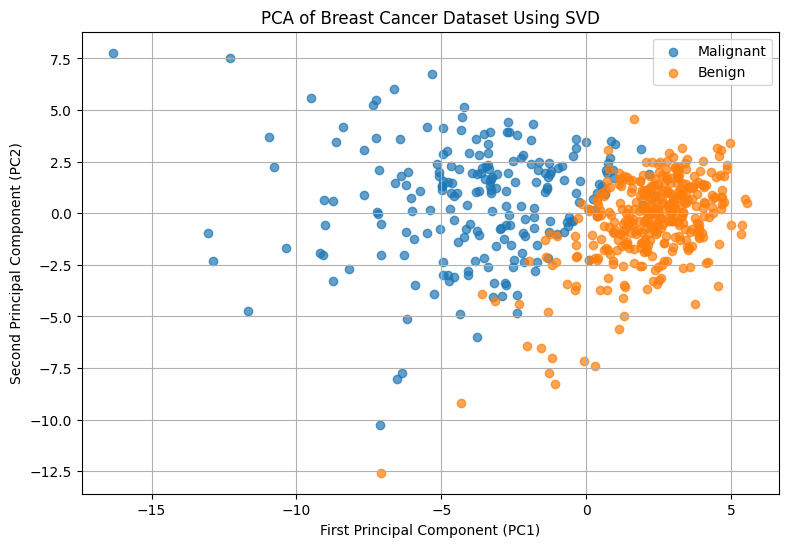

In [2]:
# Question 2: PCA via the SVD

# Standardize each feature (row)
A = (X - np.mean(X, axis=1, keepdims=True)) / np.std(X, axis=1, keepdims=True)

# Compute the SVD
U, S, VT = np.linalg.svd(A, full_matrices=False)

# Project the data onto the first two principal components
Z = U[:, :2].T @ A

# Plot the projected data
plt.figure(figsize=(9, 6))

plt.scatter(Z[0, y == 0], Z[1, y == 0],
            label='Malignant', alpha=0.7)

plt.scatter(Z[0, y == 1], Z[1, y == 1],
            label='Benign', alpha=0.7)

plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.title('PCA of Breast Cancer Dataset Using SVD')
plt.legend()
plt.grid(True)
plt.show()

Question 2: PCA via the SVD

Each feature was standardized to have a mean of 0 and a standard deviation of 1. Singular Value Decomposition (SVD) was then applied to the standardized data matrix, (A=U\Sigma V^T). The columns of (U) represent the principal components.

The scatter plot shows that the first two principal components provide reasonably good separation between benign and malignant tumours. Most malignant samples are grouped separately from benign samples, primarily along the first principal component. However, some overlap exists between the two classes, meaning the first two principal components cannot perfectly distinguish benign from malignant tumours.

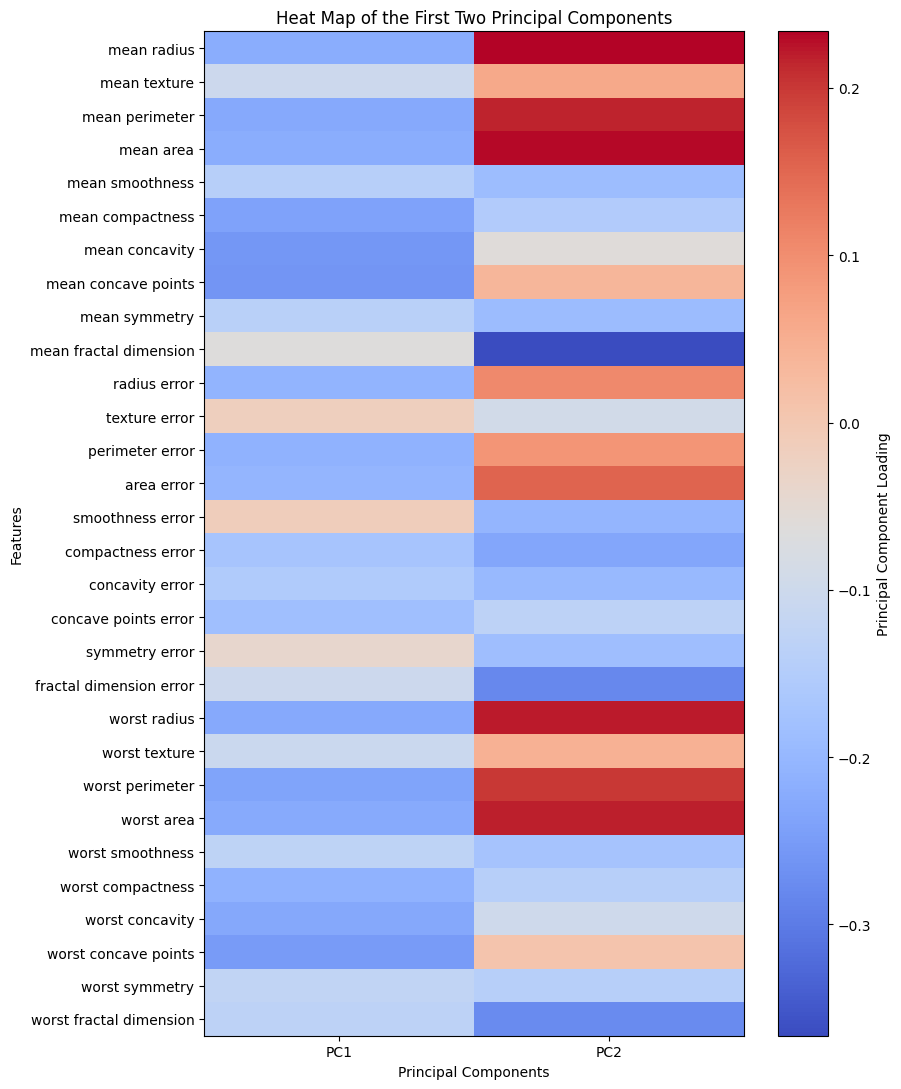

In [3]:
# Question 3: Heat Map of the First Two Principal Components

# Extract the first two principal components
PC = U[:, :2]

plt.figure(figsize=(9, 11))

plt.imshow(PC, cmap='coolwarm', aspect='auto')
plt.colorbar(label='Principal Component Loading')

plt.xticks([0, 1], ['PC1', 'PC2'])
plt.yticks(np.arange(30), cancer_data.feature_names)

plt.xlabel('Principal Components')
plt.ylabel('Features')
plt.title('Heat Map of the First Two Principal Components')

plt.tight_layout()
plt.show()

Question 3: Heat Map

The heat map shows how the 30 standardized features contribute to the first two principal components. Features with larger absolute loadings have a stronger influence on each component.

PC1 is strongly associated with measurements such as radius, perimeter, area, compactness, concavity, and concave points, particularly their mean and worst values. These features describe tumour size and shape irregularity.

PC2 shows a different pattern, with stronger contributions from features such as texture, smoothness, symmetry, and fractal dimension.

Features measuring similar characteristics, such as radius, perimeter, and area, tend to be positively correlated. Concavity and concave points also tend to be correlated. These relationships indicate that several features contain overlapping information, which PCA helps summarize using fewer dimensions.

The heat map shows that PC1 has strong contributions from radius, perimeter, area, concavity, and concave points, particularly their mean and worst measurements. PC2 has strong contributions from radius, perimeter, area, and fractal dimension, with different signs and magnitudes. Features such as radius, perimeter, and area show similar loading patterns, suggesting they are positively correlated. Concavity and concave points also have similar patterns, indicating a positive correlation. This suggests that several features contain overlapping information, which PCA helps reduce into fewer components.

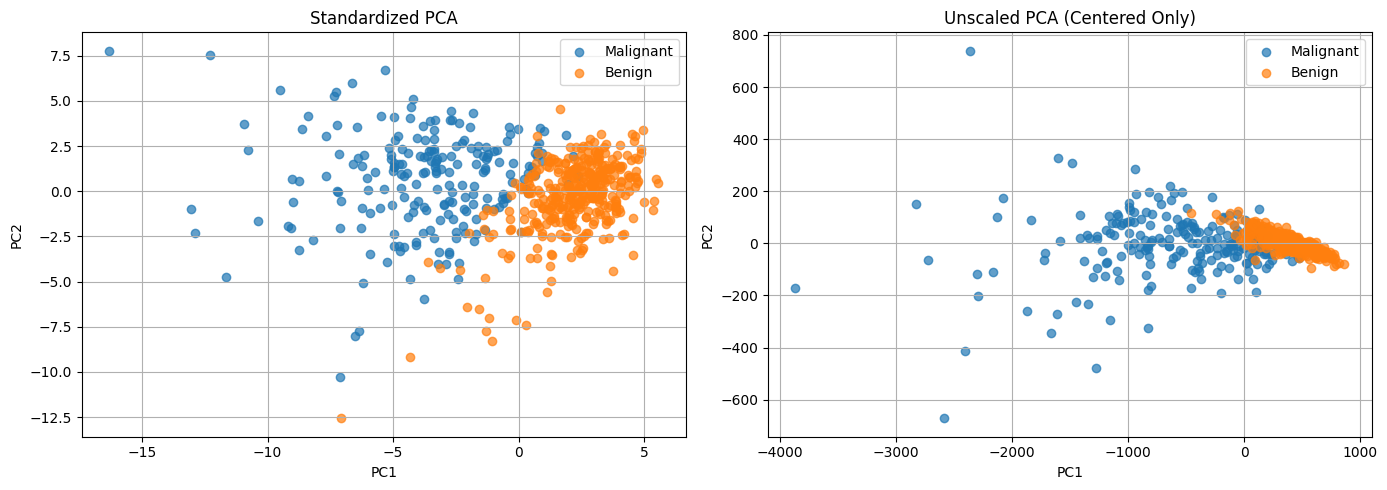

In [4]:
# Question 4: What Standardization Does

# Center the data without scaling
B = X - np.mean(X, axis=1, keepdims=True)

# Compute SVD of centered (unscaled) data
U_unscaled, S_unscaled, VT_unscaled = np.linalg.svd(
    B, full_matrices=False
)

# Project onto the first two principal components
Z_unscaled = U_unscaled[:, :2].T @ B

# Compare standardized and unscaled PCA
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Standardized PCA
axes[0].scatter(Z[0, y == 0], Z[1, y == 0],
                label='Malignant', alpha=0.7)
axes[0].scatter(Z[0, y == 1], Z[1, y == 1],
                label='Benign', alpha=0.7)

axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].set_title('Standardized PCA')
axes[0].legend()
axes[0].grid(True)

# Unscaled PCA
axes[1].scatter(Z_unscaled[0, y == 0], Z_unscaled[1, y == 0],
                label='Malignant', alpha=0.7)
axes[1].scatter(Z_unscaled[0, y == 1], Z_unscaled[1, y == 1],
                label='Benign', alpha=0.7)

axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('Unscaled PCA (Centered Only)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

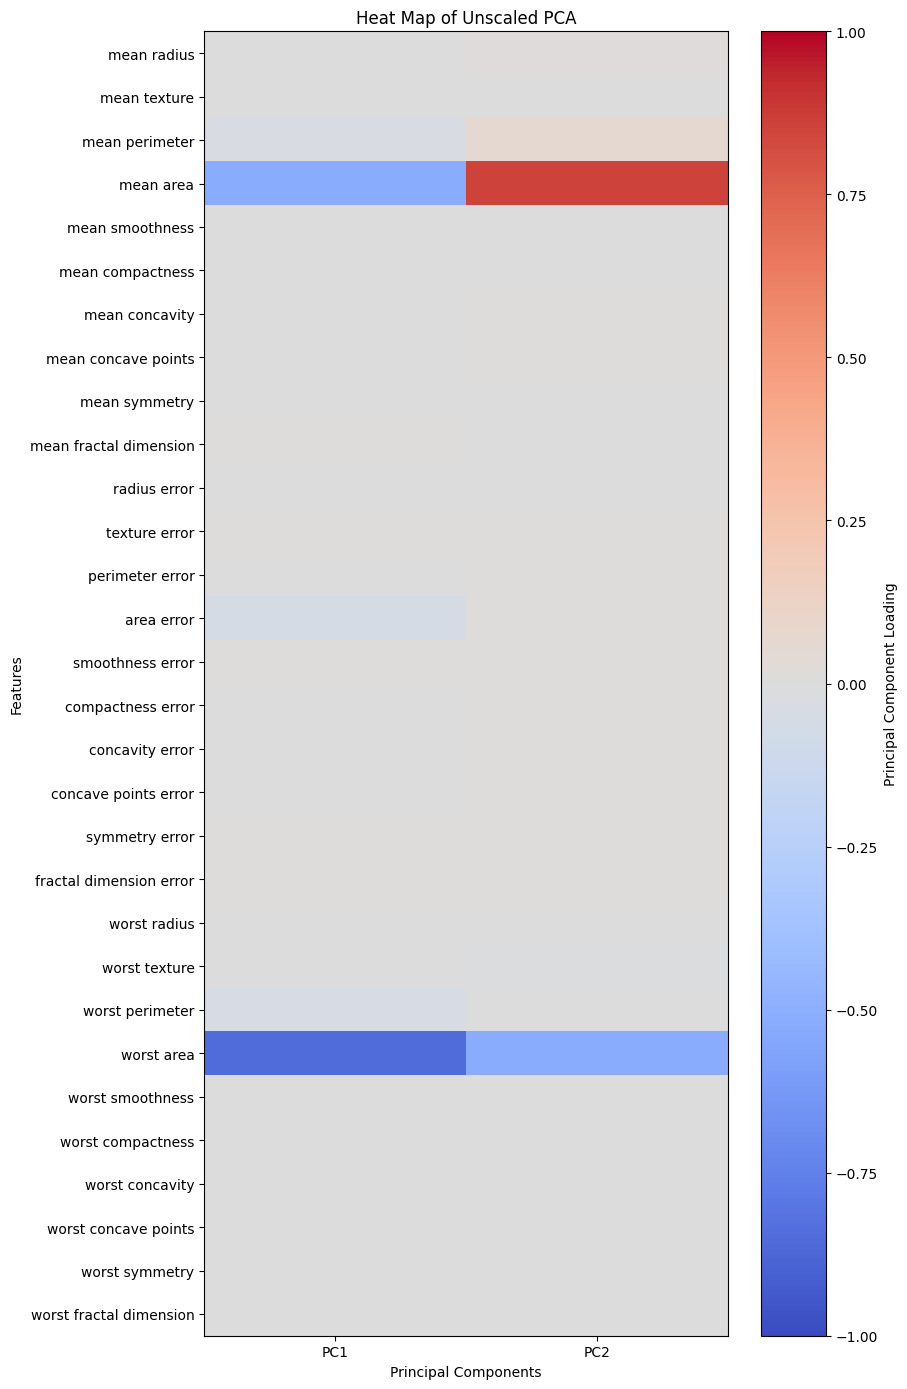

In [5]:
# Question 4: Heat Map of Unscaled Principal Components

PC_unscaled = U_unscaled[:, :2]

plt.figure(figsize=(9, 14))

plt.imshow(PC_unscaled, cmap='coolwarm',
           aspect='auto', vmin=-1, vmax=1)

plt.colorbar(label='Principal Component Loading')

plt.xticks([0, 1], ['PC1', 'PC2'])
plt.yticks(np.arange(30), cancer_data.feature_names)

plt.xlabel('Principal Components')
plt.ylabel('Features')
plt.title('Heat Map of Unscaled PCA')

plt.tight_layout()
plt.show()

In [6]:
# Examine the largest entries of the first unscaled PC

pc1 = U_unscaled[:, 0]

indices = np.argsort(np.abs(pc1))[::-1]

print("Largest loadings in unscaled PC1:\n")

for i in indices[:10]:
    print(f"{cancer_data.feature_names[i]}: {pc1[i]:.4f}")

Largest loadings in unscaled PC1:

worst area: -0.8521
mean area: -0.5168
area error: -0.0557
worst perimeter: -0.0495
mean perimeter: -0.0351
worst radius: -0.0072
mean radius: -0.0051
worst texture: -0.0031
perimeter error: -0.0022
mean texture: -0.0022


The standardized and unscaled PCA scatter plots show different distributions because standardization changes how much each feature contributes to the principal components. Standardized PCA gives each feature a mean of 0 and standard deviation of 1, while unscaled PCA only subtracts the mean.

In the unscaled PCA, the first principal component is dominated by area measurements, particularly mean area and worst area, because these features have much larger numerical variances than the other measurements. As a result, the unscaled PCA primarily captures differences in tumour size, while standardized PCA gives more influence to other characteristics such as texture, smoothness, and concavity.

Both scatter plots show some separation between benign and malignant tumours, although the distributions and degree of overlap differ.

Standardization is appropriate when features have different units or numerical scales and we want them to contribute more equally to PCA. It may not be appropriate when the original variances are meaningful or when preserving the relative importance of the measurements is necessary.

Question 5: The Original Frame

The original dataset has 30 features, so the original reference frame is 30-dimensional and cannot be directly visualized in a 2D or 3D plot. PCA reduces the data to two dimensions by projecting it onto the first two principal components, making it easier to visualize patterns and class separation. Transforming the reduced data back into the original 30-dimensional space would not restore the information lost during dimensionality reduction and would make visualization more difficult.

In [7]:
# Question 6: Connecting Code to Mathematics

from sklearn.decomposition import PCA

n = A.shape[1]

# (a) Verify C = Sigma V^T

C = U.T @ A
C_svd = np.diag(S) @ VT

print("QUESTION 6(a)")
print("Maximum difference between U^T A and Sigma V^T:")
print(np.max(np.abs(C - C_svd)))


# (b) Verify eigenvalues of covariance matrix

cov = A @ A.T / (n - 1)

eigenvalues, eigenvectors = np.linalg.eigh(cov)
eigenvalues = eigenvalues[::-1]

svd_eigenvalues = S**2 / (n - 1)

print("\nQUESTION 6(b)")
print("First 5 eigenvalues from eigh:")
print(eigenvalues[:5])

print("First 5 eigenvalues from SVD:")
print(svd_eigenvalues[:5])

print("Maximum eigenvalue difference:")
print(np.max(np.abs(eigenvalues - svd_eigenvalues)))


# (c) Compare with sklearn PCA

pca = PCA(n_components=2)
pca.fit(A.T)

print("\nQUESTION 6(c)")

print("Explained variance from sklearn:")
print(pca.explained_variance_)

print("Explained variance from SVD:")
print(svd_eigenvalues[:2])

print("Explained variance ratios from sklearn:")
print(pca.explained_variance_ratio_)

print("Explained variance ratios from SVD:")
print(svd_eigenvalues[:2] / np.sum(svd_eigenvalues))

# Compare principal component directions
for i in range(2):
    dot = np.dot(U[:, i], pca.components_[i])
    print(f"PC{i+1} direction dot product: {dot:.6f}")

print("Maximum absolute loading difference (ignoring sign):")
print(np.max(
    np.abs(np.abs(U[:, :2].T) - np.abs(pca.components_))
))

QUESTION 6(a)
Maximum difference between U^T A and Sigma V^T:
3.197442310920451e-14

QUESTION 6(b)
First 5 eigenvalues from eigh:
[13.30499079  5.7013746   2.82291016  1.98412752  1.65163324]
First 5 eigenvalues from SVD:
[13.30499079  5.7013746   2.82291016  1.98412752  1.65163324]
Maximum eigenvalue difference:
1.4210854715202004e-14

QUESTION 6(c)
Explained variance from sklearn:
[13.30499079  5.7013746 ]
Explained variance from SVD:
[13.30499079  5.7013746 ]
Explained variance ratios from sklearn:
[0.44272026 0.18971182]
Explained variance ratios from SVD:
[0.44272026 0.18971182]
PC1 direction dot product: -1.000000
PC2 direction dot product: -1.000000
Maximum absolute loading difference (ignoring sign):
3.885780586188048e-16


### Question 6(a): PC Scores

From the singular value decomposition,

\[
A=U\Sigma V^T
\]

Multiplying both sides by \(U^T\),

\[
U^TA=U^TU\Sigma V^T
\]

Since \(U^TU=I\),

\[
\boxed{C=U^TA=\Sigma V^T}
\]

The numerical check confirms that both calculations agree, with a maximum difference approximately equal to zero (\(10^{-14}\)), due to floating-point rounding.

### Question 6(b): Covariance Eigenvalues

The sample covariance matrix is

\[
S=\frac{AA^T}{n-1}
\]

Substituting \(A=U\Sigma V^T\),

\[
S=\frac{U\Sigma V^TV\Sigma^TU^T}{n-1}
\]

Since \(V^TV=I\),

\[
S=U\frac{\Sigma\Sigma^T}{n-1}U^T
\]

Therefore, the eigenvalues are

\[
\boxed{\lambda_i=\frac{\sigma_i^2}{n-1}}
\]

The numerical check using `numpy.linalg.eigh` confirms that the eigenvalues match those calculated from the singular values, with differences approximately equal to zero.

### Question 6(c): Comparison with Scikit-Learn

The principal components from our SVD calculation agree with those calculated using `sklearn.decomposition.PCA`, up to possible sign differences. The explained variances also match.

Mathematically, the principal components are eigenvectors of the covariance matrix:

\[
Su=\lambda u
\]

Multiplying both sides by \(-1\),

\[
S(-u)=\lambda(-u)
\]

Therefore, both \(u\) and \(-u\) are valid eigenvectors with the same eigenvalue. This explains why the principal components may point in opposite directions while both methods remain correct.

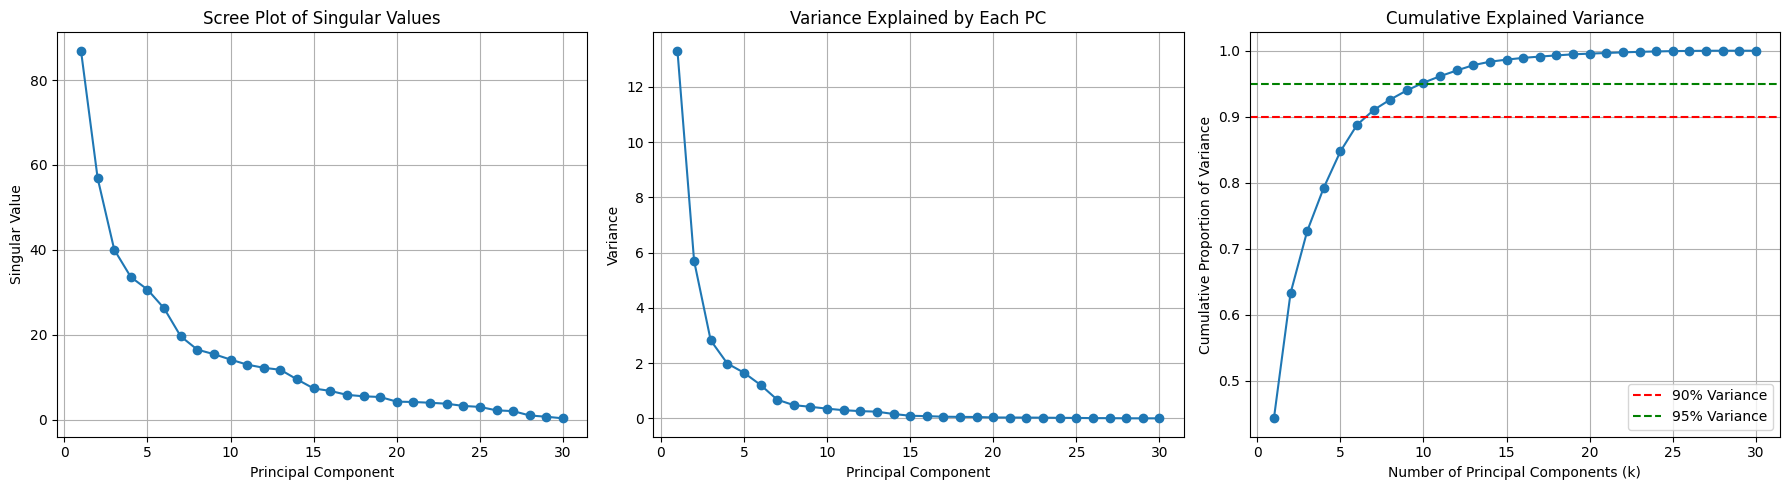

Components for 90% variance: 7
Components for 95% variance: 10
Variance explained by 7 PCs: 0.9100953006967308
Variance explained by 10 PCs: 0.9515688143366667


In [9]:
# Question 7: How Many Principal Components?

# Variance explained by each principal component
variance = S**2 / (n - 1)

# Proportion of total variance
variance_ratio = variance / np.sum(variance)

# Cumulative proportion of variance
cumulative_variance = np.cumsum(variance_ratio)

k = np.arange(1, len(S) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Scree plot of singular values
axes[0].plot(k, S, 'o-')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Singular Value')
axes[0].set_title('Scree Plot of Singular Values')
axes[0].grid(True)

# Plot 2: Variance of each principal component
axes[1].plot(k, variance, 'o-')
axes[1].set_xlabel('Principal Component')
axes[1].set_ylabel('Variance')
axes[1].set_title('Variance Explained by Each PC')
axes[1].grid(True)

# Plot 3: Cumulative proportion of variance
axes[2].plot(k, cumulative_variance, 'o-')
axes[2].axhline(0.90, color='red', linestyle='--', label='90% Variance')
axes[2].axhline(0.95, color='green', linestyle='--', label='95% Variance')
axes[2].set_xlabel('Number of Principal Components (k)')
axes[2].set_ylabel('Cumulative Proportion of Variance')
axes[2].set_title('Cumulative Explained Variance')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

# Find components needed for 90% and 95% variance
k90 = np.searchsorted(cumulative_variance, 0.90) + 1
k95 = np.searchsorted(cumulative_variance, 0.95) + 1

print("Components for 90% variance:", k90)
print("Components for 95% variance:", k95)
print("Variance explained by 7 PCs:", cumulative_variance[6])
print("Variance explained by 10 PCs:", cumulative_variance[9])

Question 7: How Many Principal Components?

The scree plot shows that the singular values decrease rapidly for the first few principal components before gradually leveling off. The variance plot confirms that the first components explain the largest amount of variation in the dataset.

I would choose 7 principal components because the scree plot begins to flatten around this region, suggesting that additional components contribute relatively little variance.

The cumulative variance plot shows that 7 components capture approximately 91.01% of the total variance, while 10 components capture approximately 95.16%.

The 90% criterion agrees with my choice of 7 components, while the 95% criterion requires 10 components. These criteria do not completely agree because the 95% threshold retains more information at the cost of additional dimensions. Seven components provide a reasonable balance between dimensionality reduction and preserving information.

Question 8(a)
Accuracy with 30 features: 0.9825
Accuracy with 2 PCs: 0.9415


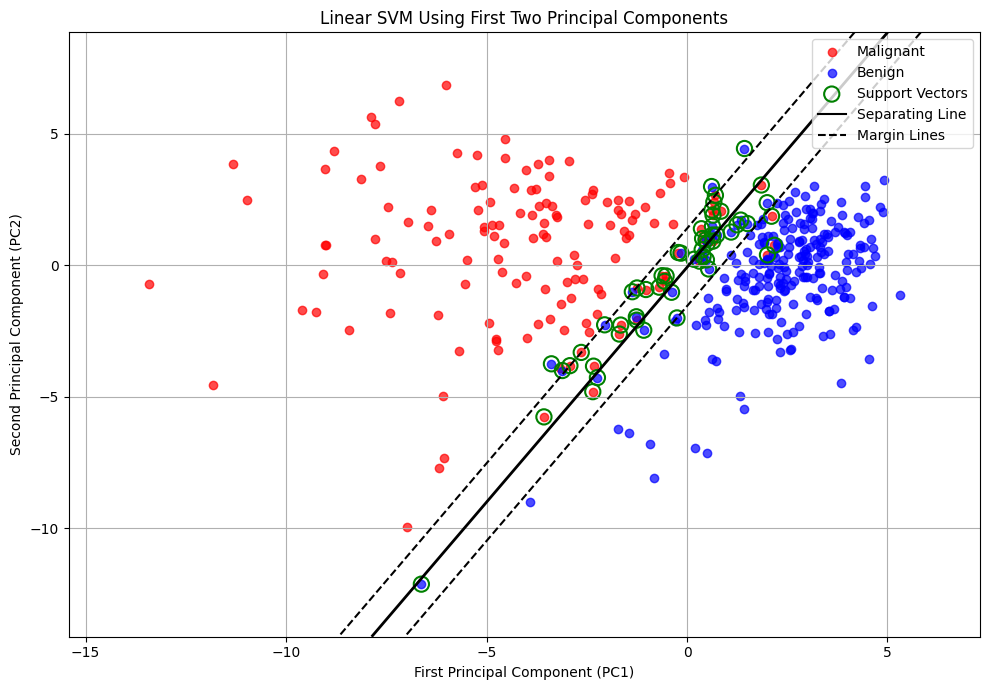


Question 8(c)
Accuracy with 7 PCs: 0.9532

Question 8(d)
Accuracy lost using 2 PCs: 4.09 percentage points


In [10]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from matplotlib.lines import Line2D

# Load the dataset
data = load_breast_cancer()
X = data.data.T
y = data.target

# Split into training (70%) and test (30%) sets
# Stratified to preserve the class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X.T, y, test_size=0.30, random_state=42, stratify=y
)

# Standardize using training data only
mean_train = np.mean(X_train, axis=0)
std_train = np.std(X_train, axis=0)

A_train = ((X_train - mean_train) / std_train).T
A_test = ((X_test - mean_train) / std_train).T

# Compute SVD using training data only
U_train, S_train, VT_train = np.linalg.svd(
    A_train, full_matrices=False
)

# Project training and test data onto principal components
C_train = U_train.T @ A_train
C_test = U_train.T @ A_test


# (a) SVM using all 30 standardized features
svm_30 = SVC(kernel='linear')
svm_30.fit(A_train.T, y_train)

pred_30 = svm_30.predict(A_test.T)
acc_30 = accuracy_score(y_test, pred_30)

# SVM using first 2 principal components
svm_2 = SVC(kernel='linear')
svm_2.fit(C_train[:2, :].T, y_train)

pred_2 = svm_2.predict(C_test[:2, :].T)
acc_2 = accuracy_score(y_test, pred_2)

print("Question 8(a)")
print(f"Accuracy with 30 features: {acc_30:.4f}")
print(f"Accuracy with 2 PCs: {acc_2:.4f}")


# (b) Plot training data, separating line, margins,
# and support vectors

plt.figure(figsize=(10, 7))

# Training samples
for label, name, color in [
    (0, 'Malignant', 'red'),
    (1, 'Benign', 'blue')
]:
    plt.scatter(
        C_train[0, y_train == label],
        C_train[1, y_train == label],
        c=color, label=name, alpha=0.7
    )

# Create a grid for the decision boundary
x_min, x_max = C_train[0].min()-2, C_train[0].max()+2
y_min, y_max = C_train[1].min()-2, C_train[1].max()+2

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
decision = svm_2.decision_function(grid).reshape(xx.shape)

# Plot separating line and margin lines
plt.contour(
    xx, yy, decision,
    levels=[-1, 0, 1],
    colors=['black', 'black', 'black'],
    linestyles=['--', '-', '--'],
    linewidths=[1.5, 2, 1.5]
)

# Mark support vectors
plt.scatter(
    svm_2.support_vectors_[:, 0],
    svm_2.support_vectors_[:, 1],
    s=120, facecolors='none',
    edgecolors='green', linewidths=1.5,
    label='Support Vectors'
)

# Add legend entries for lines
handles, labels = plt.gca().get_legend_handles_labels()

handles += [
    Line2D([0], [0], color='black', linestyle='-',
           label='Separating Line'),
    Line2D([0], [0], color='black', linestyle='--',
           label='Margin Lines')
]

plt.legend(handles=handles)
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.title('Linear SVM Using First Two Principal Components')
plt.grid(True)
plt.tight_layout()
plt.show()


# (c) SVM using 7 principal components from Question 7
k = 7

svm_7 = SVC(kernel='linear')
svm_7.fit(C_train[:k, :].T, y_train)

pred_7 = svm_7.predict(C_test[:k, :].T)
acc_7 = accuracy_score(y_test, pred_7)

print("\nQuestion 8(c)")
print(f"Accuracy with {k} PCs: {acc_7:.4f}")


# (d) Calculate accuracy lost
accuracy_lost = (acc_30 - acc_2) * 100

print("\nQuestion 8(d)")
print(f"Accuracy lost using 2 PCs: {accuracy_lost:.2f} percentage points")

Question 8(a): Classifier Accuracy

The data was split into 70% training and 30% testing using stratified sampling. Standardization and PCA were computed using only the training data to prevent data leakage.

The linear SVM using all 30 standardized features achieved a test accuracy of 98.25%, while the classifier using only the first two principal components achieved 94.15%.

Question 8(b): SVM Decision Boundary

The scatter plot shows the training samples projected onto the first two principal components. The solid line represents the SVM decision boundary, the dashed lines represent the margins, and the highlighted points are the support vectors.

The two classes show noticeable separation, although some overlap remains. The support vectors are the training samples that determine the position of the separating boundary.

Question 8(c): Seven Principal Components

Using the 7 principal components chosen in Question 7, the linear SVM achieved a test accuracy of 95.32%. This is higher than the accuracy obtained using 2 components but lower than using all 30 features.

Question 8(d): Accuracy Loss and Benefits

Reducing the data from 30 features to 2 principal components decreased test accuracy from 98.25% to 94.15%, a loss of approximately 4.09 percentage points.

Despite this reduction, using fewer features can still be beneficial because it reduces dimensionality, simplifies the model, decreases computational requirements, and allows the data to be visualized in two dimensions. The reduced model retains much of the classification performance while using considerably fewer features.